In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [73]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "Volcanic_rock_age_data.xlsx"

df = pd.read_excel(DATA_PATH)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (653, 58)


,SAMPLE,Lab,CaO,SiO2,Cr2O3,Na2O,TiO2,MnO,MgO,FeO,...,Lu,Hf,Ta,Pb,Th,U,C,M,R,T
0,KL2023-07-19-4_1,Lisbon,22.625,44.409,0.231,0.758,3.365,0.081,11.749,5.069,...,0.188,3.74,0.208,0.038,0.096,0.0176,1,0,0,3
1,KL2023-07-19-4_2,Lisbon,22.752,47.643,0.302,0.764,2.058,0.017,13.116,4.967,...,0.184,3.03,0.238,0.054,0.103,0.0157,0,1,0,3
2,KL2023-07-19-4_3,Lisbon,22.711,49.580,0.189,0.539,1.448,0.141,14.243,4.977,...,0.225,4.09,0.188,0.06,0.113,0.0135,0,0,1,3
3,KL2023-07-19-4_4,Lisbon,23.481,51.316,0.1,0.534,0.057,0.421,7.376,16.404,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,3
4,KL2023-07-19-4_5,Lisbon,23.601,51.941,0.118,0.423,0.139,0.388,7.826,15.199,...,NaN,NaN,NaN,NaN,NaN,NaN,0,1,0,3


In [77]:
df['Lab'].value_counts()

Lab
Lisbon       338
Cambridge    172
Utrecht      111
Sheffield     32
Name: count, dtype: int64

In [78]:
df['SAMPLE'].value_counts()

SAMPLE
KL2023-07-19-4_1     1
KL2023-07-19-4_2     1
KL2023-07-19-4_3     1
KL2023-07-19-4_4     1
KL2023-07-19-4_5     1
                    ..
KL2023-07-25-8_56    1
KL2023-07-25-8_57    1
KL2023-07-25-8_58    1
KL2023-07-25-8_59    1
KL2023-07-25-8_60    1
Name: count, Length: 653, dtype: int64

In [79]:
# Display the first 20 sample identifiers
display(df['SAMPLE'].head(20).to_list())

['KL2023-07-19-4_1',
 'KL2023-07-19-4_2',
 'KL2023-07-19-4_3',
 'KL2023-07-19-4_4',
 'KL2023-07-19-4_5',
 'KL2023-07-19-4_6',
 'KL2023-07-19-4_7',
 'KL2023-07-19-4_8',
 'KL2023-07-19-4_9',
 'KL2023-07-19-4_10',
 'KL2023-07-19-4_11',
 'KL2023-07-19-4_12',
 'KL2023-07-19-4_13',
 'KL2023-07-19-4_14',
 'KL2023-07-19-4_15',
 'KL2023-07-19-4_16',
 'KL2023-07-19-4_17',
 'KL2023-07-19-4_18',
 'KL2023-07-19-4_19',
 'KL2023-07-19-4_20']

In [80]:
sample_parts = df['SAMPLE'].str.extract(
    r'^(?P<prefix>.*?)(?P<date>\d{4}-\d{2}-\d{2})-(?P<group>\d+)_?(?P<record>\d+)?$'
)

display(sample_parts.head(20))

,prefix,date,group,record
0,KL,2023-07-19,4,1
1,KL,2023-07-19,4,2
2,KL,2023-07-19,4,3
3,KL,2023-07-19,4,4
4,KL,2023-07-19,4,5
5,KL,2023-07-19,4,6
6,KL,2023-07-19,4,7
7,KL,2023-07-19,4,8
8,KL,2023-07-19,4,9
9,KL,2023-07-19,4,10


In [81]:
sample_parts = df['SAMPLE'].str.extract(
    r'^(?P<prefix>.*?)(?P<date>\d{4}-\d{2}-\d{2})-(?P<group>\d+)_?(?P<record>\d+)?$'
)

df_check = df.join(sample_parts.add_prefix('ID_'))

group_summary = (
    df_check.groupby(['ID_date', 'ID_group'], dropna=False)
    .agg(
        observations=('SAMPLE', 'size'),
        unique_records=('ID_record', 'nunique'),
        unique_targets=('T', 'nunique')
    )
    .reset_index()
)

display(group_summary)

,ID_date,ID_group,observations,unique_records,unique_targets
0,2023-07-19,4,28,28,1
1,2023-07-19,6,39,39,1
2,2023-07-20,1,33,33,1
3,2023-07-21,3,29,29,1
4,2023-07-23,3,74,74,1
5,2023-07-23,4,46,46,1
6,2023-07-23,7,65,65,1
7,2023-07-23,8,77,77,1
8,2023-07-25,1,68,68,1
9,2023-07-25,3,73,73,1


In [82]:
date_target_summary = (
    df_check.groupby('ID_date')
    .agg(
        observations=('SAMPLE', 'size'),
        unique_groups=('ID_group', 'nunique'),
        unique_targets=('T', 'nunique')
    )
    .reset_index()
)

display(date_target_summary)

,ID_date,observations,unique_groups,unique_targets
0,2023-07-19,67,2,1
1,2023-07-20,33,1,1
2,2023-07-21,29,1,1
3,2023-07-23,262,4,1
4,2023-07-25,262,4,1


In [83]:
date_class_summary = (
    df_check.groupby('ID_date')
    .agg(
        observations=('SAMPLE', 'size'),
        target_class=('T', 'first'),
        unique_targets=('T', 'nunique')
    )
    .reset_index()
)

display(date_class_summary)

,ID_date,observations,target_class,unique_targets
0,2023-07-19,67,3,1
1,2023-07-20,33,3,1
2,2023-07-21,29,3,1
3,2023-07-23,262,1,1
4,2023-07-25,262,2,1


In [85]:
# Number of observations for each Lab and target class
lab_age_counts = pd.crosstab(
    df['Lab'],
    df['T'],
    margins=True
)

display(lab_age_counts)

T,1,2,3,All
Lab,,,,
Cambridge,64,68,40,172
Lisbon,130,158,50,338
Sheffield,23,0,9,32
Utrecht,45,36,30,111
All,262,262,129,653


In [86]:
# Percentage distribution of target classes within each Lab
lab_age_percentages = pd.crosstab(
    df['Lab'],
    df['T'],
    normalize='index'
) * 100

display(lab_age_percentages.round(2))

T,1,2,3
Lab,,,
Cambridge,37.21,39.53,23.26
Lisbon,38.46,46.75,14.79
Sheffield,71.88,0.00,28.12
Utrecht,40.54,32.43,27.03


In [87]:
lab_date_counts = pd.crosstab(
    df_check['ID_date'],
    df_check['Lab'],
    margins=True
)

display(lab_date_counts)

Lab,Cambridge,Lisbon,Sheffield,Utrecht,All
ID_date,,,,,
2023-07-19,25,28,6,8,67
2023-07-20,15,15,3,0,33
2023-07-21,0,7,0,22,29
2023-07-23,64,130,23,45,262
2023-07-25,68,158,0,36,262
All,172,338,32,111,653


In [89]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

# Contingency table without totals
lab_age = pd.crosstab(df['Lab'], df['T'])

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(lab_age)

# Cramér's V
n = lab_age.to_numpy().sum()
min_dimension = min(lab_age.shape[0] - 1, lab_age.shape[1] - 1)

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Cramér's V:", round(cramers_v, 3))

# Inspect expected counts
expected_df = pd.DataFrame(
    expected,
    index=lab_age.index,
    columns=lab_age.columns
)

print("\nExpected counts under independence:")
display(expected_df.round(2))

Chi-square statistic: 36.214
Degrees of freedom: 6
p-value: 2.505284883329669e-06
Cramér's V: 0.167

Expected counts under independence:


T,1,2,3
Lab,,,
Cambridge,69.01,69.01,33.98
Lisbon,135.61,135.61,66.77
Sheffield,12.84,12.84,6.32
Utrecht,44.54,44.54,21.93


In [90]:
print("Minimum expected count:", expected.min())
print("Expected cells below 5:", (expected < 5).sum())
print("Total cells:", expected.size)

Minimum expected count: 6.3215926493108725
Expected cells below 5: 0
Total cells: 12


In [91]:
print("Dataset shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print(col)

Dataset shape: (653, 58)

Columns:
SAMPLE
Lab
CaO
SiO2
Cr2O3
Na2O
TiO2
MnO
MgO
FeO
Al2O3
K2O
Mg#
Li
Be
B
Mg
Si
Ca
Ca.1
Sc
Ti
V
Cr
Mn
Co
Ni
Cu
Rb
Sr
Y
Zr
Nb
Cs
Ba
La
Ce
Pr
Nd
Sm
Eu
Gd
Tb
Dy
Ho
Er
Tm
Yb
Lu
Hf
Ta
Pb
Th
U
C
M
R
T


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 653 entries, 0 to 652
Data columns (total 58 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SAMPLE  653 non-null    str    
 1   Lab     653 non-null    str    
 2   CaO     653 non-null    float64
 3   SiO2    653 non-null    float64
 4   Cr2O3   653 non-null    object 
 5   Na2O    653 non-null    float64
 6   TiO2    653 non-null    float64
 7   MnO     653 non-null    float64
 8   MgO     653 non-null    float64
 9   FeO     653 non-null    float64
 10  Al2O3   653 non-null    float64
 11  K2O     653 non-null    float64
 12  Mg#     653 non-null    float64
 13  Li      189 non-null    object 
 14  Be      189 non-null    object 
 15  B       189 non-null    object 
 16  Mg      189 non-null    float64
 17  Si      189 non-null    float64
 18  Ca      189 non-null    float64
 19  Ca.1    189 non-null    float64
 20  Sc      189 non-null    float64
 21  Ti      189 non-null    float64
 22  V       189 n

In [4]:
df.describe()

,CaO,SiO2,Na2O,TiO2,MnO,MgO,FeO,Al2O3,K2O,Mg#,...,Yb,Lu,Hf,Ta,Th,U,C,M,R,T
count,653.000000,653.000000,653.000000,653.000000,653.000000,653.000000,653.000000,653.000000,653.000000,653.000000,...,189.000000,189.000000,189.000000,189.000000,189.000000,189.000000,653.000000,653.000000,653.000000,653.000000
mean,22.582830,46.549740,0.739581,2.283781,0.126763,12.171799,6.777258,8.347863,0.013542,0.758129,...,2.238481,0.314528,6.489947,0.895355,0.385261,0.063220,0.366003,0.277182,0.356815,1.796325
std,0.591206,2.228311,0.242971,0.705746,0.066892,1.817863,1.990485,1.895385,0.014604,0.082425,...,0.751222,0.122235,2.852992,0.951882,0.485427,0.095794,0.482080,0.447950,0.479427,0.747092
min,20.260000,39.168000,0.226000,0.057000,0.017000,5.911000,3.856000,0.536000,0.000000,0.423080,...,0.661000,0.083700,1.470000,0.080800,0.026400,0.008300,0.000000,0.000000,0.000000,1.000000
25%,22.200000,45.186100,0.606000,1.806000,0.088000,11.250000,5.498000,7.030000,0.003000,0.732560,...,1.650000,0.218000,4.380000,0.306000,0.154000,0.025000,0.000000,0.000000,0.000000,1.000000
50%,22.579000,46.681000,0.668608,2.211500,0.112000,12.501000,6.211000,8.425000,0.010000,0.781610,...,2.220000,0.301000,5.980000,0.648000,0.256000,0.040200,0.000000,0.000000,0.000000,2.000000
75%,23.019000,48.116600,0.778000,2.691000,0.144000,13.404000,7.380000,9.625000,0.022000,0.811110,...,2.690000,0.388000,7.860000,1.111000,0.427000,0.064200,1.000000,1.000000,1.000000,2.000000
max,24.455000,51.973000,1.940000,4.961000,0.587000,15.988000,16.404000,14.837000,0.161000,0.876290,...,4.010000,0.638000,18.040000,5.180000,3.440000,0.720000,1.000000,1.000000,1.000000,3.000000


In [5]:
df.drop(['SAMPLE','Lab'], axis=1, inplace=True)

C:\Users\Saha\AppData\Local\Temp\ipykernel_21228\3561130961.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['SAMPLE','Lab'], axis=1, inplace=True)


Several columns were initially identified as having an ‘object’ data type during inspection using df.info(), despite representing numerical measurements. Upon manual inspection, these columns contained values with non-numeric characters (e.g., ‘<2.3’), which prevented proper numeric interpretation. To address this, non-numeric symbols (‘<’, ‘>’) were removed using regular expressions, and the columns were subsequently converted to floating-point format. This ensured consistency in data types and allowed the features to be correctly used in machine learning models.

While removing ‘<’ and ‘>’ symbols simplifies the values, it assumes the recorded threshold values approximate the true measurements, which is a reasonable simplification for this analysis.

In [6]:
obj_col = ['Li', 'Be', 'B', 'Cr', 'Ni', 'Cu', 'Rb', 'Cs','Pb','Ba']

In [8]:
import re

raw_df = pd.read_excel(DATA_PATH)

def find_non_numeric_entries(dataframe, columns):
    """Scan specified columns in a DataFrame and find unique values that cannot be parsed as numeric.

    This helper identifies threshold labels (such as '<0.52' or '>100') or other textual entries
    that interfere with numerical calculations, excluding missing values (NaN).

    Parameters:
    ----------
    dataframe : pandas.DataFrame
        The DataFrame containing the geochemical dataset.
    columns : list of str
        List of column names to check for non-numeric entries.

    Returns:
    ------
    dict
        A dictionary mapping column names to lists of unique non-numeric values found.
    """
    non_numeric_rows = {}
    for col in columns:
        # Find entries that cannot be directly cast to float or contain special characters
        # using regex or to_numeric coercion detection
        coerced = pd.to_numeric(dataframe[col], errors='coerce')
        anomalous_mask = coerced.isna() & dataframe[col].notna()
        if anomalous_mask.any():
            non_numeric_rows[col] = dataframe.loc[anomalous_mask, col].unique().tolist()
    return non_numeric_rows

non_numeric_summary = find_non_numeric_entries(raw_df, obj_col)
print("Detected non-numeric values per column in raw data:")
for col, vals in non_numeric_summary.items():
    print(f"{col}: {vals}")

Detected non-numeric values per column in raw data:
Li: ['<0.52', '<1.19']
Be: ['<0.28', '<0.50', '<0.286', '<0.33', '<0.32', '<0.44', '<0.53', '<0.29', '<0.30', '<0.34', '<0.233', '<0.220', '<0.38']
B: ['<2.87', '<2.93', '<2.84', '<2.96', '<2.62', '<2.71', '<2.31', '<2.36', '<2.47', '<2.13', '<2.85', '<2.59', '<2.68', '<2.54', '<2.64', '<2.51', '<2.34', '<3.26', '<3.10', '<2.75', '<2.91', '<2.98', '<3.20', '<3.04', '<2.45', '<2.83', '<2.44', '<3.00', '<3.24', '<3.16', '<3.15', '<3.44', '<3.05', '<3.01', '<2.92', '<3.35', '<3.46', '<3.14', '<3.18', '<3.22', '<3.03', '<2.78', '<2.61', '<2.77', '<2.76', '<2.69', '<4.32', '<4.12', '<4.10', '<3.59', '<3.76', '<3.47', '<4.37', '<4.36', '<3.94', '<3.95', '<3.21', '<3.27', '<3.49', '<3.33', '<3.42', '<3.52', '<2.70', '<2.86', '<2.89', '<3.08', '<3.88', '<3.85', '<3.72', '<3.66', '<3.60', '<3.56', '<3.74', '<3.62', '<3.31', '<3.71', '<3.41', '<3.50', '<2.99', '<3.02', '<2.73', '<2.90', '<2.79', '<2.80', '<2.67', '<2.81']
Cr: ['<1.74', '<1.60',

### Cleaning Censored Numeric Values
Uses `.str.replace()` with regex to remove `<` and `>` characters from string values before converting them to floats. Unlike `.replace()`, which operates on DataFrame values by default, `.str.replace()` performs element-wise string replacement.

In [9]:
df[obj_col] = (df[obj_col].astype(str).replace(r'[<>]', '', regex=True).astype(float))

In [10]:
# Cr2O3 contains residual non-numeric entries not caught by the regex above.
df['Cr2O3'] = pd.to_numeric(df['Cr2O3'], errors='coerce')
print("Missing Cr2O3 values:", df['Cr2O3'].isna().sum())

Missing Cr2O3 values: 1


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 653 entries, 0 to 652
Data columns (total 56 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CaO     653 non-null    float64
 1   SiO2    653 non-null    float64
 2   Cr2O3   652 non-null    float64
 3   Na2O    653 non-null    float64
 4   TiO2    653 non-null    float64
 5   MnO     653 non-null    float64
 6   MgO     653 non-null    float64
 7   FeO     653 non-null    float64
 8   Al2O3   653 non-null    float64
 9   K2O     653 non-null    float64
 10  Mg#     653 non-null    float64
 11  Li      189 non-null    float64
 12  Be      189 non-null    float64
 13  B       189 non-null    float64
 14  Mg      189 non-null    float64
 15  Si      189 non-null    float64
 16  Ca      189 non-null    float64
 17  Ca.1    189 non-null    float64
 18  Sc      189 non-null    float64
 19  Ti      189 non-null    float64
 20  V       189 non-null    float64
 21  Cr      189 non-null    float64
 22  Mn      189 n

In [12]:
len(df.columns)

56

### Feature Sets and Target

- **EMPA (`empa_col`):** 11 major-element oxide and ratio features. One missing `Cr2O3` measurement is retained and handled through median imputation within the model pipelines.
- **LAS (`las_col`):** 41 trace-element features from Laser Ablation Spectroscopy. Only observations with complete LAS measurements and a known target are retained.
- **Target (`T`):** Categorical volcanic rock age class (1, 2, or 3).

In [13]:
empa_col = ['CaO', 'SiO2', 'Cr2O3', 'Na2O', 'TiO2', 'MnO', 'MgO', 'FeO', 'Al2O3', 'K2O', 'Mg#']

las_col = ['Li', 'Be', 'B', 'Mg', 'Si', 'Ca', 'Ca.1', 'Sc', 'Ti',
           'V', 'Cr', 'Mn', 'Co', 'Ni', 'Cu', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Cs',
           'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er',
           'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'Pb', 'Th', 'U']

T = ['T']

In [14]:
# EMPA: retain rows with a known target, allowing feature imputation
df_empa = df.loc[
    df['T'].notna(),
    empa_col + T
].copy()

# LAS: retain rows with complete LAS measurements and a known target
df_las = df.loc[
    df[las_col].notna().all(axis=1) & df['T'].notna(),
    las_col + T
].copy()

In [15]:
print(f"Shape of EMPA: {df_empa.shape}")
print(f"Shape of LAS: {df_las.shape}")

Shape of EMPA: (653, 12)
Shape of LAS: (189, 42)


In [16]:
print(f"Duplicated values in EMPA: {int(df_empa.duplicated().sum())}")
print(f"Duplicated values in LAS: {int(df_las.duplicated().sum())}")

Duplicated values in EMPA: 4
Duplicated values in LAS: 61


In [17]:
df_empa[df_empa.duplicated(subset=empa_col)] # Displays duplicated EMPA rows. subset=empa_col excludes the T column.

,CaO,SiO2,Cr2O3,Na2O,TiO2,MnO,MgO,FeO,Al2O3,K2O,Mg#,T
135,22.598,48.746,0.250,0.582,1.532,0.105,14.131,4.882,6.058,0.002,0.83871,1
605,22.430,49.614,0.065,0.764,1.412,0.151,13.526,7.085,4.945,0.002,0.77083,2
606,23.126,46.832,0.069,0.709,2.099,0.068,13.154,5.858,8.827,0.012,0.80000,2
607,23.054,47.189,0.096,0.640,2.038,0.075,12.527,6.406,8.136,0.006,0.78409,2


In [18]:
df_las[df_las.duplicated(subset=las_col)] # Displays duplicated LAS rows. subset=las_col excludes the T column.

,Li,Be,B,Mg,Si,Ca,Ca.1,Sc,Ti,V,...,Er,Tm,Yb,Lu,Hf,Ta,Pb,Th,U,T
14,0.52,0.310,2.87,89280.11,220070.69,161599.52,164381.22,94.13,12726.38,361.77,...,2.26,0.261,1.51,0.188,3.74,0.208,0.038,0.096,0.0176,3
15,1.59,0.280,2.93,93192.75,220410.17,160831.94,164381.22,93.43,10796.43,312.03,...,1.56,0.201,1.41,0.184,3.03,0.238,0.054,0.103,0.0157,3
16,1.88,0.155,2.84,97795.37,226428.56,159958.36,164381.22,93.26,8539.11,257.09,...,2.08,0.234,1.64,0.225,4.09,0.188,0.060,0.113,0.0135,3
23,1.88,0.155,2.84,97795.37,226428.56,159958.36,164381.22,93.26,8539.11,257.09,...,2.08,0.234,1.64,0.225,4.09,0.188,0.060,0.113,0.0135,3
56,2.34,0.680,2.31,62652.67,204918.86,162202.16,164381.22,24.88,10331.69,296.09,...,2.28,0.294,2.24,0.310,7.68,0.685,0.078,0.178,0.0330,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
612,7.15,2.480,2.84,40927.28,187607.67,163210.42,164381.17,11.56,18708.39,374.07,...,4.21,0.577,4.01,0.597,13.05,5.180,0.284,0.724,0.0730,2
613,19.30,0.560,2.86,73140.32,201304.09,163643.84,164381.19,65.48,14949.76,294.55,...,2.37,0.278,1.83,0.214,5.68,0.594,0.131,0.260,0.0314,2
650,9.03,0.380,2.80,90324.70,215612.05,161709.22,164381.19,61.58,7423.53,206.42,...,1.32,0.164,1.07,0.131,2.46,0.286,0.170,0.256,0.0361,2
651,1.67,0.670,2.67,80453.15,204705.73,161215.83,164381.17,55.60,13002.61,223.59,...,2.46,0.312,1.69,0.256,5.45,0.658,0.204,0.389,0.0554,2


In [19]:
def find_duplicate_columns(dataframe):
    """Identifies duplicate columns within a pandas DataFrame.

    This function transposes the DataFrame to leverage pandas' row-based
    duplicated-checking mechanism on the column vectors, identifying any
    columns with identical sequences of values.

    Parameters:
    ----------
    dataframe : pandas.DataFrame
        The input DataFrame to inspect for duplicate columns.

    Returns:
    ------
    tuple:
        - int: The total count of duplicate columns found.
        - list of str: A list of the duplicate column names (excluding the
          first occurrences).
    """
    # Transpose the DataFrame to treat columns as rows and then find duplicates
    duplicate_column_mask = dataframe.T.duplicated()

    # Get the names of the duplicate columns
    duplicate_column_names = dataframe.T[duplicate_column_mask].index.tolist()

    return duplicate_column_mask.sum(), duplicate_column_names

In [20]:
num_duplicates_empa, names_duplicates_empa = find_duplicate_columns(df_empa)

print(f"Number of duplicate columns in df_empa: {num_duplicates_empa}")
print(f"Names of duplicate columns in df_empa: {names_duplicates_empa}")

num_duplicates_las, names_duplicates_las = find_duplicate_columns(df_las)

print(f"\nNumber of duplicate columns in df_las: {num_duplicates_las}")
print(f"Names of duplicate columns in df_las: {names_duplicates_las}")

Number of duplicate columns in df_empa: 0
Names of duplicate columns in df_empa: []

Number of duplicate columns in df_las: 0
Names of duplicate columns in df_las: []


Duplicated values were found in dataset but kept those values as instructed by supervisor.

**DATA VISUALISATION**

### Correlation Analysis: EMPA and LAS
Pearson correlation heatmaps illustrate relationships between the geochemical features in the EMPA and LAS datasets. The target variable, T, is excluded because it represents categorical age classes rather than a continuous numerical measurement. The EMPA heatmap covers 11 oxide and ratio features, while the LAS heatmap covers 41 trace-element features. Strong correlations may indicate multicollinearity; for example, Mg# is derived from MgO and FeO, while rare-earth elements may co-vary because of shared geochemical behaviour. These relationships are examined for exploratory purposes, and no features are removed at this stage.

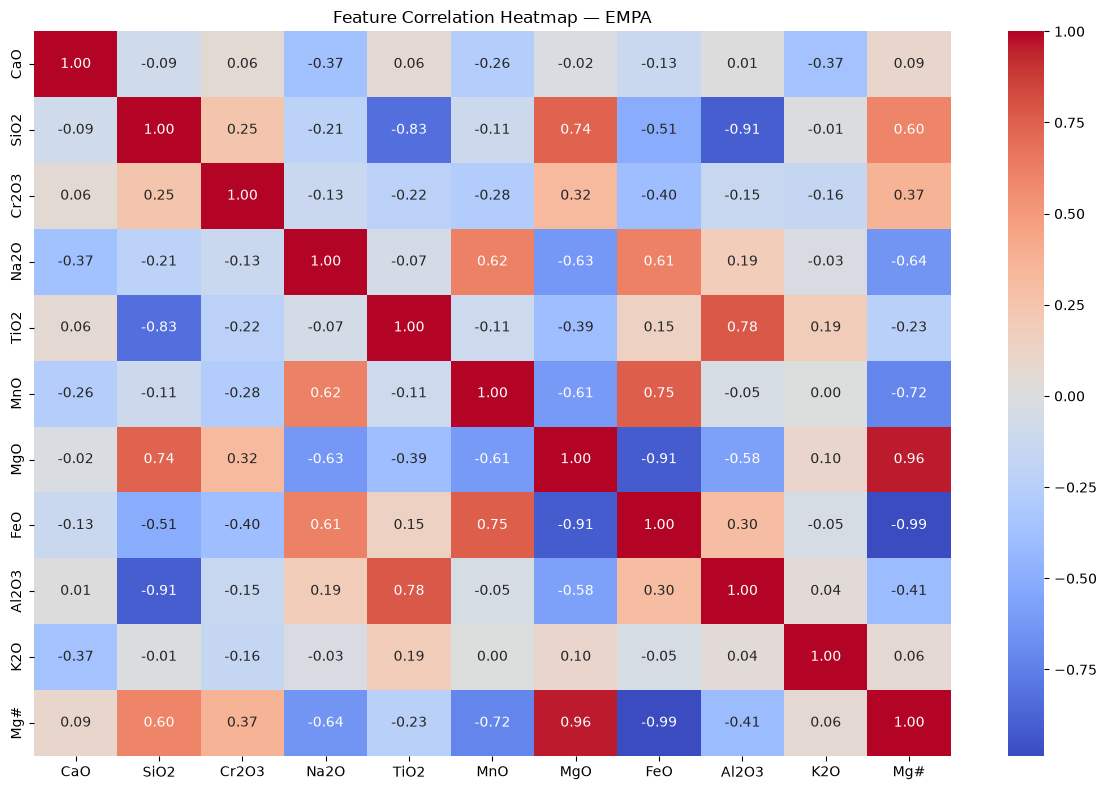

In [22]:
# Calculate correlations between EMPA features only (exclude target T)
import seaborn as sns
corr_empa = df_empa[empa_col].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_empa, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Feature Correlation Heatmap — EMPA')
plt.tight_layout()
plt.show()

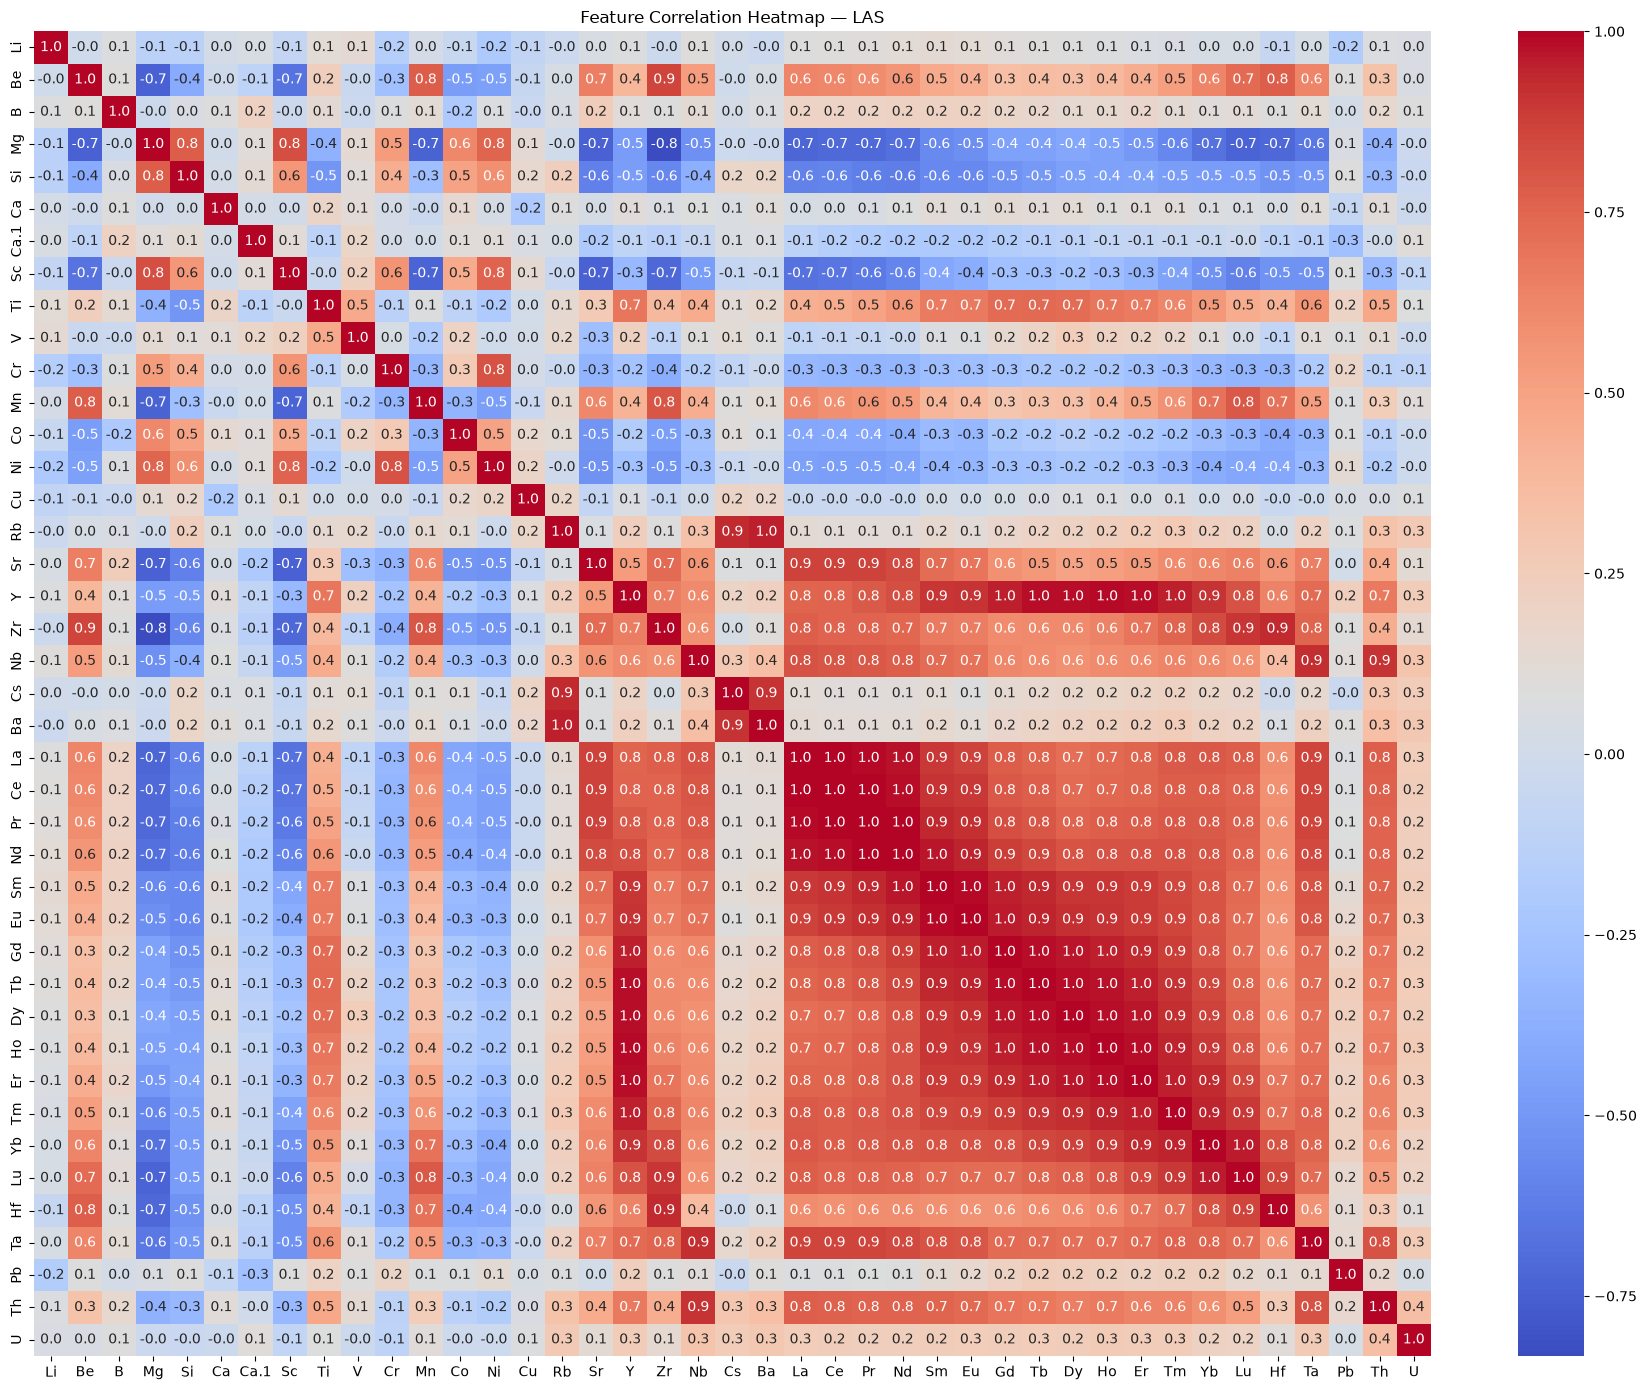

In [23]:
# Calculate correlations between LAS features only (exclude target T)
corr_las = df_las[las_col].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr_las, cmap='coolwarm', annot=True, fmt='.1f')
plt.title('Feature Correlation Heatmap — LAS')
plt.tight_layout()
plt.show()

### Class Distribution of Target

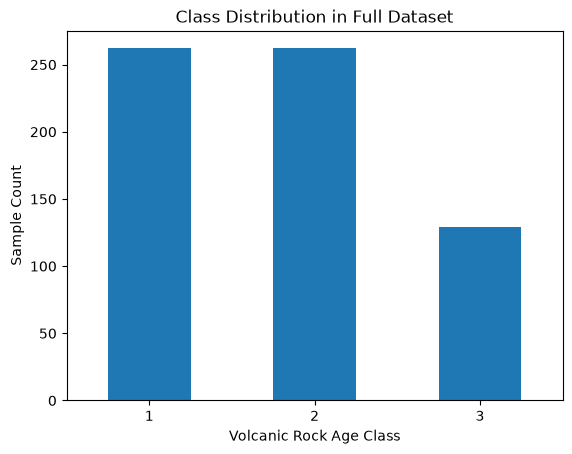

In [24]:
df['T'].value_counts().sort_index().plot(kind='bar')
plt.xticks(rotation=0)
plt.xlabel('Volcanic Rock Age Class')
plt.ylabel('Sample Count')
plt.title('Class Distribution in Full Dataset')
plt.show()

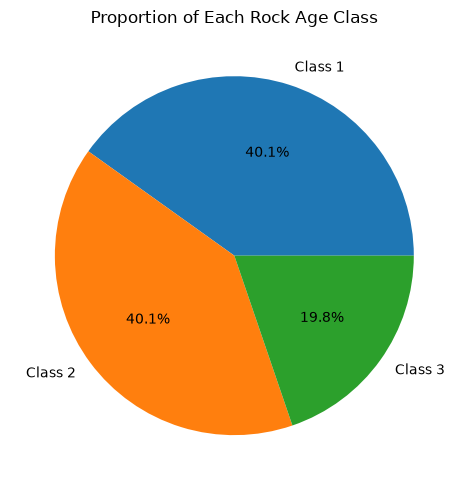

In [25]:
fig, ax = plt.subplots(figsize=(5,5))
df['T'].value_counts().sort_index().plot(kind='pie', autopct='%1.1f%%',
    labels=['Class 1','Class 2','Class 3'], ax=ax)
ax.set_ylabel('')
ax.set_title('Proportion of Each Rock Age Class')
plt.tight_layout(); plt.show()

### Target Distribution and Class Imbalance
The target variable (T) contains approximately 260 samples each for classes 1 and 2, compared with 130 samples for class 3. This imbalance can bias models towards majority classes, reducing recall and F1-score for class 3. Class weighting was applied to selected models to help mitigate this issue and improve minority-class classification.

### Pairplot

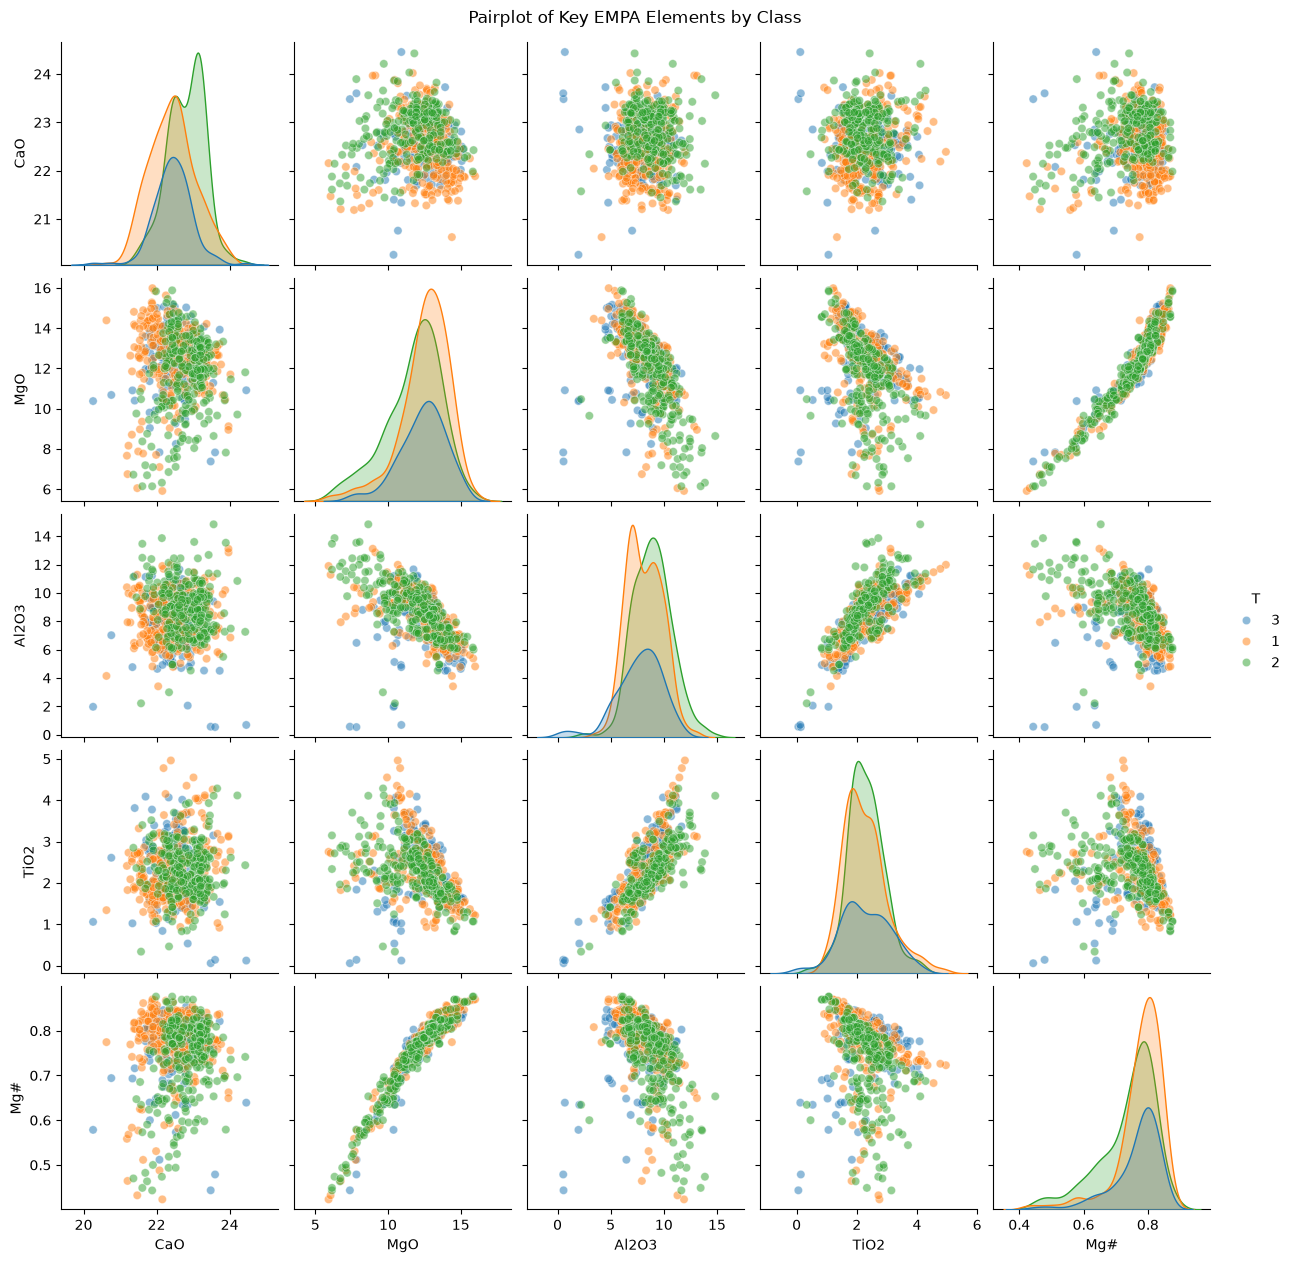

In [26]:
key_features = ['CaO','MgO','Al2O3','TiO2','Mg#']
pair_df = df_empa[key_features + ['T']].copy()
pair_df['T'] = pair_df['T'].astype(str)
sns.pairplot(pair_df, hue='T', diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle('Pairplot of Key EMPA Elements by Class', y=1.01)
plt.show()

### Train-Test Split
The C, M, and R location identifiers were removed before training to prevent location-related data leakage. Experiments, particularly with XGBoost on LAS data, showed unrealistically high performance when these features were included, suggesting the model was learning location-specific patterns rather than generalisable geochemical relationships. Removing them supports a fairer evaluation of model performance.

In [27]:
from sklearn.model_selection import train_test_split

X_empa, y_empa  = df_empa.drop(['T'], axis=1), df_empa['T']
X_las, y_las = df_las.drop(['T'], axis=1), df_las['T']

X_train_empa, X_test_empa, y_train_empa, y_test_empa = train_test_split(
                                                                          X_empa,
                                                                          y_empa,
                                                                          test_size=0.2,
                                                                          random_state=42,
                                                                          stratify=y_empa                                                                )


X_train_las, X_test_las, y_train_las, y_test_las = train_test_split(
                                                                      X_las,
                                                                      y_las,
                                                                      test_size=0.2,
                                                                      random_state=42,
                                                                      stratify=y_las
                                                                      )

`StratifiedKFold` maintains class proportions in each fold, handles class imbalance. Particularly important here because class 3 is a minority class.

In [28]:
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

`LabelEncoder()` transform labels. XGBoost requires 0-based integer labels {0, 1, 2} rather than {1, 2, 3}.

In [ ]:
# from sklearn.preprocessing import LabelEncoder

# le_empa = LabelEncoder()

# y_empa_enc = le_empa.fit_transform(y_empa)
# y_train_empa_enc = le_empa.fit_transform(y_train_empa)
# y_test_empa_enc = le_empa.transform(y_test_empa)

# le_las = LabelEncoder()

# y_las_enc = le_las.fit_transform(y_las)
# y_train_las_enc = le_las.fit_transform(y_train_las)
# y_test_las_enc = le_las.transform(y_test_las)

In [92]:
from sklearn.preprocessing import LabelEncoder

# EMPA
le_empa = LabelEncoder()
y_train_empa_enc = le_empa.fit_transform(y_train_empa)
y_test_empa_enc = le_empa.transform(y_test_empa)

# LAS
le_las = LabelEncoder()
y_train_las_enc = le_las.fit_transform(y_train_las)
y_test_las_enc = le_las.transform(y_test_las)

In [30]:
def evaluate_model(model, X_test, y_test, title="Model", class_names=None, label_encoder=None):

    y_pred = model.predict(X_test)

    # Decode if encoder provided
    if label_encoder is not None:
        y_pred = label_encoder.inverse_transform(y_pred)

    print(f"{title} Accuracy:", accuracy_score(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    if class_names is None:
        class_names = sorted(set(y_test))

    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'{title} Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return y_pred, cm

### Logistic Regression
A linear baseline for three-class classification. The pipeline applies `StandardScaler` before logistic regression to standardise features with different magnitudes. `class_weight='balanced'` addresses class imbalance, `solver='lbfgs'` supports multinomial classification, and `max_iter=1000` allows sufficient iterations for convergence.

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

logr_empa = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

logr_las= Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

### Random Forest Classifier
An ensemble of 300 decision trees trained using bagging. Handles nonlinear relationships and requires no feature scaling. `class_weight='balanced'` helps address class imbalance, while `random_state=42` ensures reproducibility. Feature importance is used to interpret influential features.

In [32]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_empa = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42
    ))
])

rf_las = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42
    ))
])

### XGBoost Classifier
Gradient-boosted decision trees for multiclass classification. Key parameters: `n_estimators=300`, `max_depth=4`, and `learning_rate=0.05` control boosting and model complexity. `subsample=0.8` and `colsample_bytree=0.8` introduce randomness to reduce overfitting. `eval_metric='mlogloss'` specifies multiclass log loss.

In [33]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_empa = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='mlogloss',
        random_state=42
    ))
])

xgb_las = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='mlogloss',
        random_state=42
    ))
])

### MLP Neural Network
A fully connected neural network with hidden layers of 128, 64, and 32 neurons. The pipeline combines `StandardScaler` with an `MLPClassifier` to ensure consistent preprocessing without data leakage. ReLU activation, the Adam optimiser, and L2 regularisation support training and generalisation. Early stopping monitors a validation split, with `max_iter=500` as the upper training limit. Separate pipelines are used for EMPA and LAS to fit preprocessing independently.

In [34]:
from sklearn.neural_network import MLPClassifier

def build_mlp_pipeline(hidden_layers=(128, 64, 32)):
    """
    Returns a Pipeline with:
      - StandardScaler: normalises features to zero mean, unit variance
      - MLPClassifier: feedforward neural network with 3 hidden layers,
        ReLU activation, Adam optimiser, early stopping on validation loss
    """
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(
            hidden_layer_sizes=hidden_layers,  # 3 hidden layers: 128 → 64 → 32
            activation='relu',                 # ReLU — standard for deep networks
            solver='adam',                     # Adam optimiser
            alpha=1e-4,                        # L2 regularisation (weight decay)
            batch_size=32,                     # mini-batch gradient descent
            learning_rate='adaptive',          # halves LR when loss stops improving
            learning_rate_init=1e-3,           # initial learning rate
            max_iter=500,                      # maximum epochs
            early_stopping=True,               # stop when val loss plateaus
            validation_fraction=0.15,          # 15% of train used for early stopping
            n_iter_no_change=20,               # patience: 20 epochs without improvement
            random_state=42,
            verbose=False
        ))
    ])

# Instantiate separate pipelines for each dataset
mlp_empa = build_mlp_pipeline(hidden_layers=(128, 64, 32))
mlp_las  = build_mlp_pipeline(hidden_layers=(128, 64, 32))

### Cross-Validation

The four classifiers—Logistic Regression, Random Forest, XGBoost, and a multilayer perceptron (MLP)—are evaluated using five-fold stratified cross-validation on the training data. Performance is assessed using accuracy, macro-precision, macro-recall, and macro-F1, with macro-F1 used to rank the models. Preprocessing is performed within each model pipeline to avoid information leakage between training and validation folds. Class imbalance is addressed using balanced class weights for Logistic Regression and Random Forest, and fold-specific balanced sample weights for XGBoost.

In [52]:
from sklearn.base import clone

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.utils.class_weight import compute_sample_weight

models = {
    "Logistic Regression": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            solver='lbfgs',
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric='mlogloss',
            random_state=42
        ))
    ]),

    # Uses the same pipeline and hyperparameters as cell 59
    "MLP": build_mlp_pipeline(
        hidden_layers=(128, 64, 32)
    )
}


# --------------------------------------------------
# 2. Define evaluation metrics
# --------------------------------------------------

scoring = {
    'Accuracy': accuracy_score,
    'Precision': lambda y_true, y_pred: precision_score(
        y_true, y_pred, average='macro', zero_division=0
    ),
    'Recall': lambda y_true, y_pred: recall_score(
        y_true, y_pred, average='macro', zero_division=0
    ),
    'F1': lambda y_true, y_pred: f1_score(
        y_true, y_pred, average='macro', zero_division=0
    )
}


# --------------------------------------------------
# 3. Run stratified cross-validation
#    XGBoost receives fold-specific balanced weights
# --------------------------------------------------

def run_cv(models, X, y, dataset_name, cv):
    results = []

    for model_name, pipeline in models.items():

        fold_scores = {
            metric: [] for metric in scoring
        }

        for train_idx, val_idx in cv.split(X, y):

            X_fold_train = X.iloc[train_idx]
            X_fold_val = X.iloc[val_idx]

            y_fold_train = y[train_idx]
            y_fold_val = y[val_idx]

            # Create a fresh model for this fold
            model = clone(pipeline)

            # Calculate balanced sample weights using
            # ONLY this fold's training labels
            if model_name == "XGBoost":
                sample_weights = compute_sample_weight(
                    class_weight='balanced',
                    y=y_fold_train
                )

                model.fit(
                    X_fold_train,
                    y_fold_train,
                    model__sample_weight=sample_weights
                )

            else:
                model.fit(
                    X_fold_train,
                    y_fold_train
                )

            # Predict the validation fold
            y_pred = model.predict(X_fold_val)

            # Calculate evaluation metrics
            for metric_name, metric_function in scoring.items():
                score = metric_function(y_fold_val, y_pred)
                fold_scores[metric_name].append(score)

        # Summarise the five validation folds
        results.append({
            'Dataset': dataset_name,
            'Model': model_name,
            'Accuracy': np.mean(fold_scores['Accuracy']),
            'Precision': np.mean(fold_scores['Precision']),
            'Recall': np.mean(fold_scores['Recall']),
            'F1': np.mean(fold_scores['F1']),
            'Std (F1)': np.std(fold_scores['F1'], ddof=0)
        })

    results_df = pd.DataFrame(results)

    return results_df.sort_values(
        by='F1',
        ascending=False
    ).reset_index(drop=True)


# --------------------------------------------------
# 4. EMPA cross-validation
# --------------------------------------------------

results_empa_cv = run_cv(
    models=models,
    X=X_train_empa,
    y=y_train_empa_enc,
    dataset_name='EMPA',
    cv=skf
)

print("EMPA — 5-Fold Stratified Cross-Validation")
display(results_empa_cv.round(3))


# --------------------------------------------------
# 5. LAS cross-validation
# --------------------------------------------------

results_las_cv = run_cv(
    models=models,
    X=X_train_las,
    y=y_train_las_enc,
    dataset_name='LAS',
    cv=skf
)

print("LAS — 5-Fold Stratified Cross-Validation")
display(results_las_cv.round(3))

EMPA — 5-Fold Stratified Cross-Validation


,Dataset,Model,Accuracy,Precision,Recall,F1,Std (F1)
0,EMPA,MLP,0.805,0.787,0.775,0.775,0.057
1,EMPA,Random Forest,0.749,0.736,0.731,0.729,0.043
2,EMPA,XGBoost,0.745,0.720,0.717,0.714,0.065
3,EMPA,Logistic Regression,0.711,0.692,0.694,0.685,0.038


LAS — 5-Fold Stratified Cross-Validation


,Dataset,Model,Accuracy,Precision,Recall,F1,Std (F1)
0,LAS,Logistic Regression,0.841,0.867,0.851,0.841,0.047
1,LAS,Random Forest,0.808,0.815,0.812,0.808,0.061
2,LAS,XGBoost,0.801,0.814,0.805,0.800,0.061
3,LAS,MLP,0.782,0.814,0.783,0.782,0.093


### Logistic Regression training- EMPA & LAS

In [53]:
logr_empa.fit(X_train_empa, y_train_empa)
logr_las.fit(X_train_las, y_train_las)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](41,)","['Li','Be','B',...,'Pb','Th','U']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a 

### Random forest training- EMPA & LAS

In [54]:
rf_empa.fit(X_train_empa, y_train_empa)
rf_las.fit(X_train_las, y_train_las)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[1,2,3]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](41,)","['Li','Be','B',...,'Pb','Th','U']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string

### XGBoost training- EMPA & LAS
**Class Weighting and Label Encoding**

`compute_sample_weight('balanced', y_train_empa_enc)` assigns higher weights to samples from minority classes. These weights are passed to XGBoost through `.fit(sample_weight=...)` to help address class imbalance. The target labels are encoded as integers starting from 0, as required by XGBoost for multiclass classification.

In [55]:
from sklearn.utils.class_weight import compute_sample_weight

# EMPA: calculate balanced sample weights
sample_weights_empa = compute_sample_weight(
    class_weight='balanced',
    y=y_train_empa_enc
)

xgb_empa.fit(
    X_train_empa,
    y_train_empa_enc,
    model__sample_weight=sample_weights_empa
)

# LAS: calculate balanced sample weights
sample_weights_las = compute_sample_weight(
    class_weight='balanced',
    y=y_train_las_enc
)

xgb_las.fit(
    X_train_las,
    y_train_las_enc,
    model__sample_weight=sample_weights_las
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](41,)","['Li','Be','B',...,'Pb','Th','U']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,41
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string

### MLP Training: EMPA and LAS
The MLP is trained separately on the EMPA and LAS training sets using the original class labels (1, 2, 3), which `MLPClassifier` supports natively. The `n_iter_` attribute reports the actual number of iterations completed. If it reaches `max_iter=500`, the model may not have converged, so consider increasing the limit or inspecting the loss curve.

In [56]:
mlp_empa.fit(X_train_empa, y_train_empa)
print(f"EMPA MLP trained — stopped at epoch: "
      f"{mlp_empa.named_steps['mlp'].n_iter_}")

# Train on LAS
mlp_las.fit(X_train_las, y_train_las)
print(f"LAS  MLP trained — stopped at epoch: "
      f"{mlp_las.named_steps['mlp'].n_iter_}")

EMPA MLP trained — stopped at epoch: 34
LAS  MLP trained — stopped at epoch: 39


### Model Evaluation and Comparison
`evaluate_models()` evaluates multiple fitted models using `evaluate_model()`, collecting accuracy and F1-scores into a DataFrame for comparison and visualisation. For XGBoost models, the label encoder converts predictions from `{0, 1, 2}` back to the original class labels `{1, 2, 3}`.

In [57]:
def evaluate_models(models, X_test, y_test, label_encoder=None):
    results = {}

    for name, model in models.items():

        # Handle XGBoost (encoded labels)
        if "XGB" in name and label_encoder is not None:
            y_pred, _ = evaluate_model(
                model,
                X_test,
                y_test,
                title=name,
                label_encoder=label_encoder
            )
        else:
            y_pred, _ = evaluate_model(
                model,
                X_test,
                y_test,
                title=name
            )

        results[name] = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "F1_macro": f1_score(y_test, y_pred, average='macro')
        }

    return pd.DataFrame(results).T

### Model Dictionaries: EMPA and LAS
Dictionaries map display names to trained model objects for consistent evaluation using `evaluate_models()`. Separate dictionaries are maintained for EMPA and LAS to enable side-by-side performance comparison across datasets.

In [58]:
models_empa = {
    "LogR (EMPA)": logr_empa,
    "RF (EMPA)": rf_empa,
    "XGB (EMPA)": xgb_empa,
    "MLP (EMPA)": mlp_empa
}

models_las = {
    "LogR (LAS)": logr_las,
    "RF (LAS)": rf_las,
    "XGB (LAS)": xgb_las,
    "MLP (LAS)": mlp_las
}

LogR (EMPA) Accuracy: 0.6564885496183206

Classification Report:
              precision    recall  f1-score   support

           1       0.68      0.51      0.58        53
           2       0.75      0.85      0.79        52
           3       0.47      0.58      0.52        26

    accuracy                           0.66       131
   macro avg       0.63      0.64      0.63       131
weighted avg       0.66      0.66      0.65       131



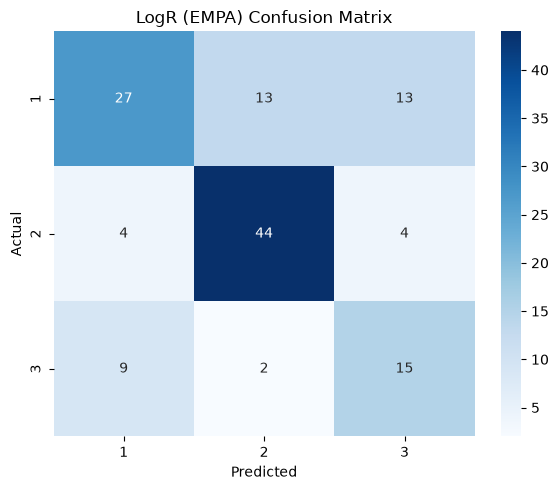

RF (EMPA) Accuracy: 0.7175572519083969

Classification Report:
              precision    recall  f1-score   support

           1       0.73      0.70      0.71        53
           2       0.71      0.81      0.76        52
           3       0.71      0.58      0.64        26

    accuracy                           0.72       131
   macro avg       0.72      0.69      0.70       131
weighted avg       0.72      0.72      0.71       131



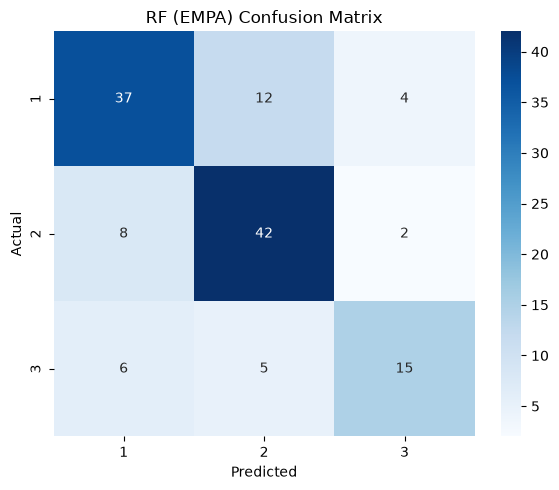

XGB (EMPA) Accuracy: 0.732824427480916

Classification Report:
              precision    recall  f1-score   support

           1       0.77      0.68      0.72        53
           2       0.70      0.90      0.79        52
           3       0.76      0.50      0.60        26

    accuracy                           0.73       131
   macro avg       0.74      0.69      0.70       131
weighted avg       0.74      0.73      0.72       131



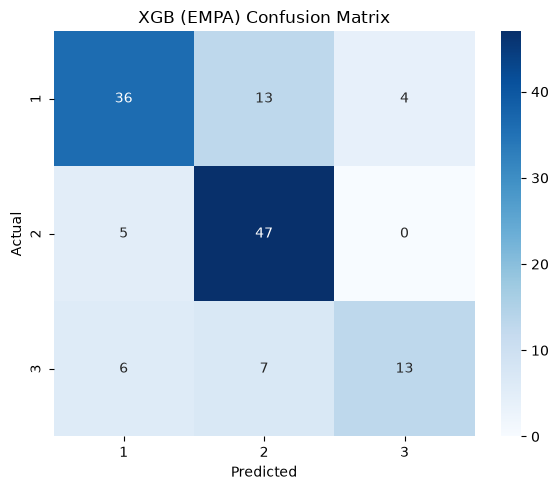

MLP (EMPA) Accuracy: 0.7175572519083969

Classification Report:
              precision    recall  f1-score   support

           1       0.70      0.74      0.72        53
           2       0.69      0.87      0.77        52
           3       1.00      0.38      0.56        26

    accuracy                           0.72       131
   macro avg       0.80      0.66      0.68       131
weighted avg       0.76      0.72      0.71       131



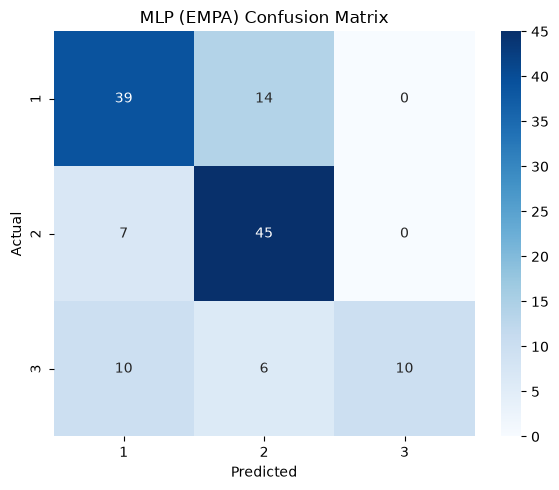

EMPA Results:
             Accuracy  F1_macro
LogR (EMPA)  0.656489  0.630226
RF (EMPA)    0.717557  0.702198
XGB (EMPA)   0.732824  0.704856
MLP (EMPA)   0.717557  0.680128


In [59]:
results_empa = evaluate_models(
    models_empa,
    X_test_empa,
    y_test_empa,
    label_encoder=le_empa
)

print("EMPA Results:")
print(results_empa)

LogR (LAS) Accuracy: 0.868421052631579

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.81      0.84        16
           2       0.75      0.90      0.82        10
           3       1.00      0.92      0.96        12

    accuracy                           0.87        38
   macro avg       0.87      0.88      0.87        38
weighted avg       0.88      0.87      0.87        38



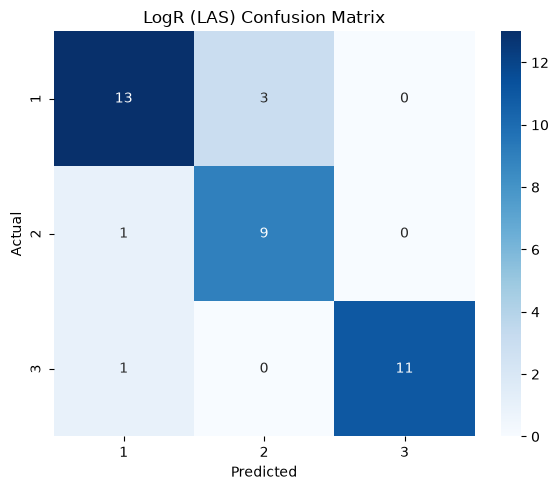

RF (LAS) Accuracy: 0.868421052631579

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.81      0.84        16
           2       0.73      0.80      0.76        10
           3       1.00      1.00      1.00        12

    accuracy                           0.87        38
   macro avg       0.86      0.87      0.87        38
weighted avg       0.87      0.87      0.87        38



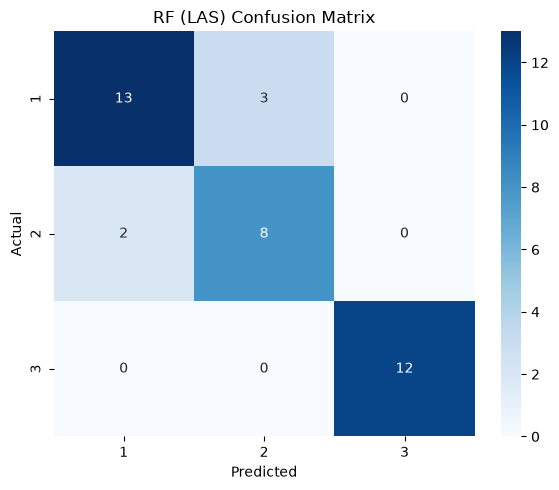

XGB (LAS) Accuracy: 0.8947368421052632

Classification Report:
              precision    recall  f1-score   support

           1       0.93      0.81      0.87        16
           2       0.75      0.90      0.82        10
           3       1.00      1.00      1.00        12

    accuracy                           0.89        38
   macro avg       0.89      0.90      0.89        38
weighted avg       0.90      0.89      0.90        38



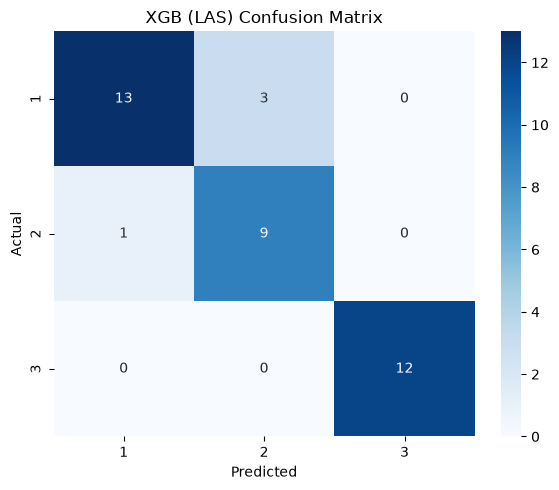

MLP (LAS) Accuracy: 0.868421052631579

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.81      0.84        16
           2       0.75      0.90      0.82        10
           3       1.00      0.92      0.96        12

    accuracy                           0.87        38
   macro avg       0.87      0.88      0.87        38
weighted avg       0.88      0.87      0.87        38



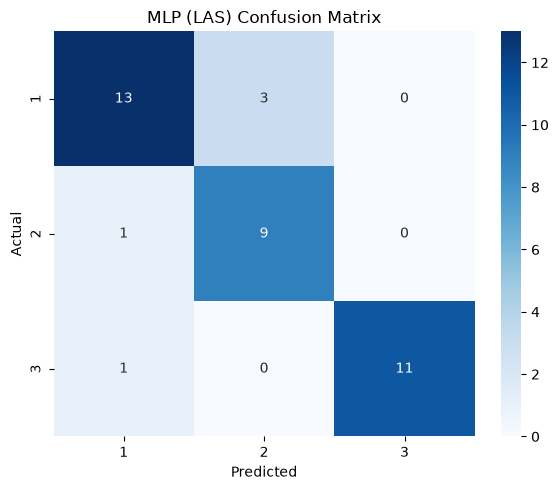

LAS Results:
            Accuracy  F1_macro
LogR (LAS)  0.868421  0.871138
RF (LAS)    0.868421  0.866871
XGB (LAS)   0.894737  0.894949
MLP (LAS)   0.868421  0.871138


In [60]:
results_las = evaluate_models(
    models_las,
    X_test_las,
    y_test_las,
    label_encoder=le_las
)

print("LAS Results:")
print(results_las)

### Model Accuracy Comparison: EMPA vs LAS
A grouped bar chart compares the test-set accuracy of the four classification models across EMPA and LAS datasets. Using a shared y-axis enables direct comparison of model performance between datasets.

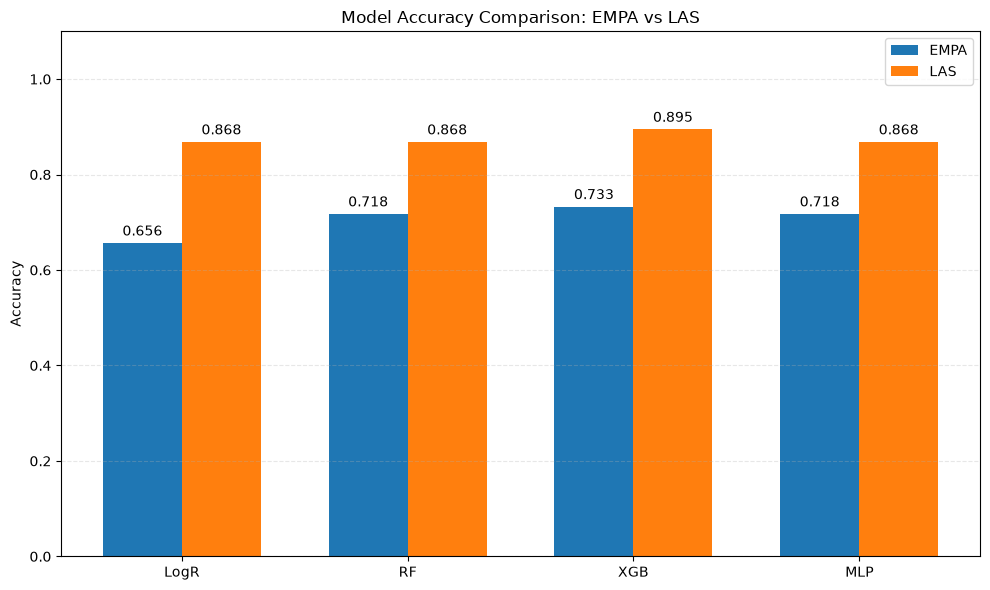

In [61]:
model_labels = ['LogR', 'RF', 'XGB', 'MLP']

x = np.arange(len(model_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars_empa = ax.bar(
    x - width / 2,
    results_empa['Accuracy'].values,
    width,
    label='EMPA'
)

bars_las = ax.bar(
    x + width / 2,
    results_las['Accuracy'].values,
    width,
    label='LAS'
)

ax.bar_label(bars_empa, fmt='%.3f', padding=3)
ax.bar_label(bars_las, fmt='%.3f', padding=3)

ax.set_title('Model Accuracy Comparison: EMPA vs LAS')
ax.set_ylabel('Accuracy')
ax.set_xticks(x)
ax.set_xticklabels(model_labels)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### MLP Training Loss Curves
Plots the training loss across epochs for both EMPA and LAS MLP models using `.loss_curve_`. A decreasing loss indicates that the model is learning, while a plateau may suggest convergence or the need for further hyperparameter tuning. These curves help assess training progress but do not independently confirm good generalisation.

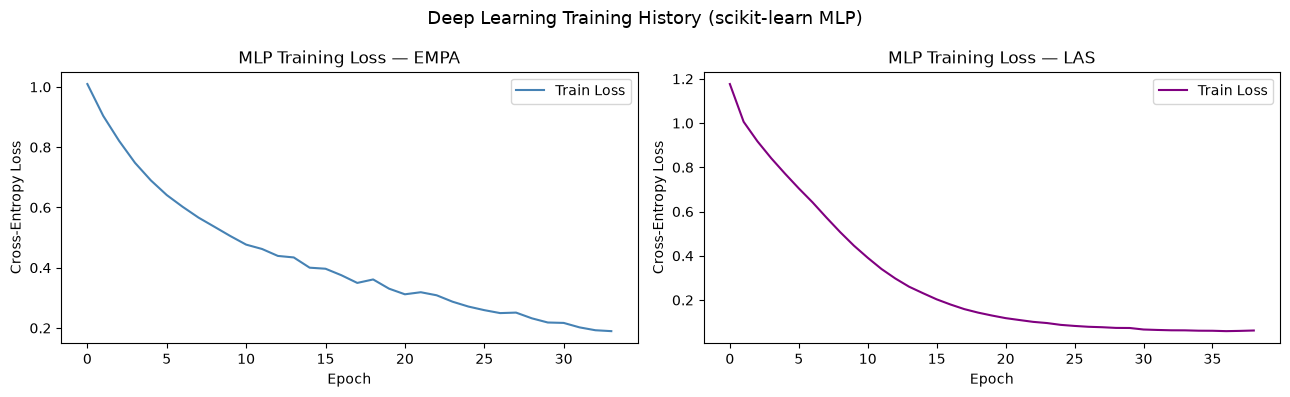

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# EMPA loss curve
axes[0].plot(mlp_empa.named_steps['mlp'].loss_curve_, label='Train Loss', color='steelblue')
axes[0].set_title('MLP Training Loss — EMPA')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

# LAS loss curve
axes[1].plot(mlp_las.named_steps['mlp'].loss_curve_, label='Train Loss', color='purple')
axes[1].set_title('MLP Training Loss — LAS')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cross-Entropy Loss')
axes[1].legend()

plt.suptitle('Deep Learning Training History (scikit-learn MLP)', fontsize=13)
plt.tight_layout()
plt.show()

### Feature Importance: EMPA Random Forest
Uses `.feature_importances_` to measure each feature's contribution to reducing impurity across the decision trees. Higher values indicate greater relative importance for class separation.

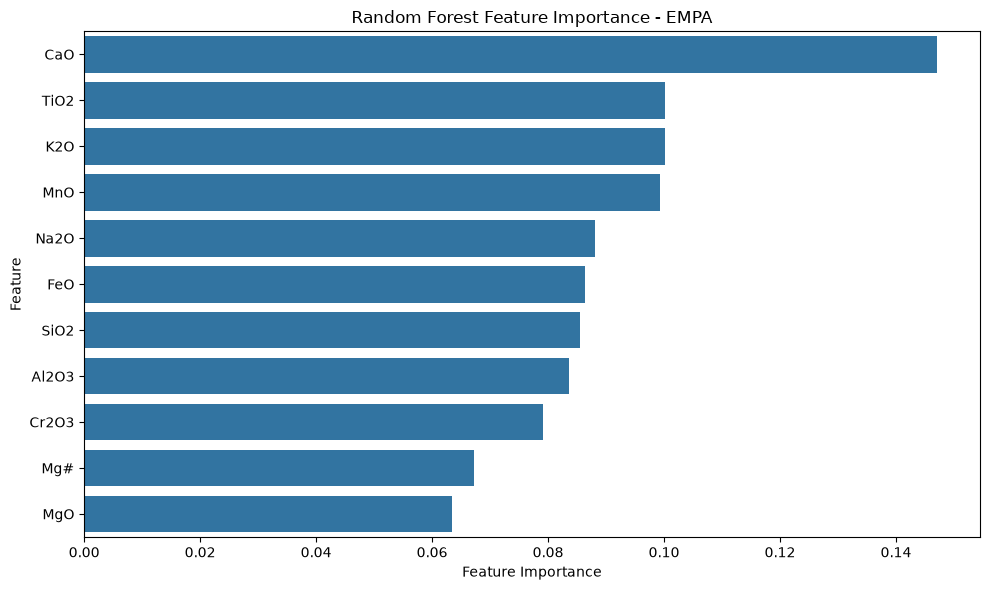

In [63]:
# Extract feature importances from the Random Forest inside each pipeline
importance_empa = pd.Series(
    rf_empa.named_steps['model'].feature_importances_,
    index=X_empa.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importance_empa.values, y=importance_empa.index)
plt.title('Random Forest Feature Importance - EMPA')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

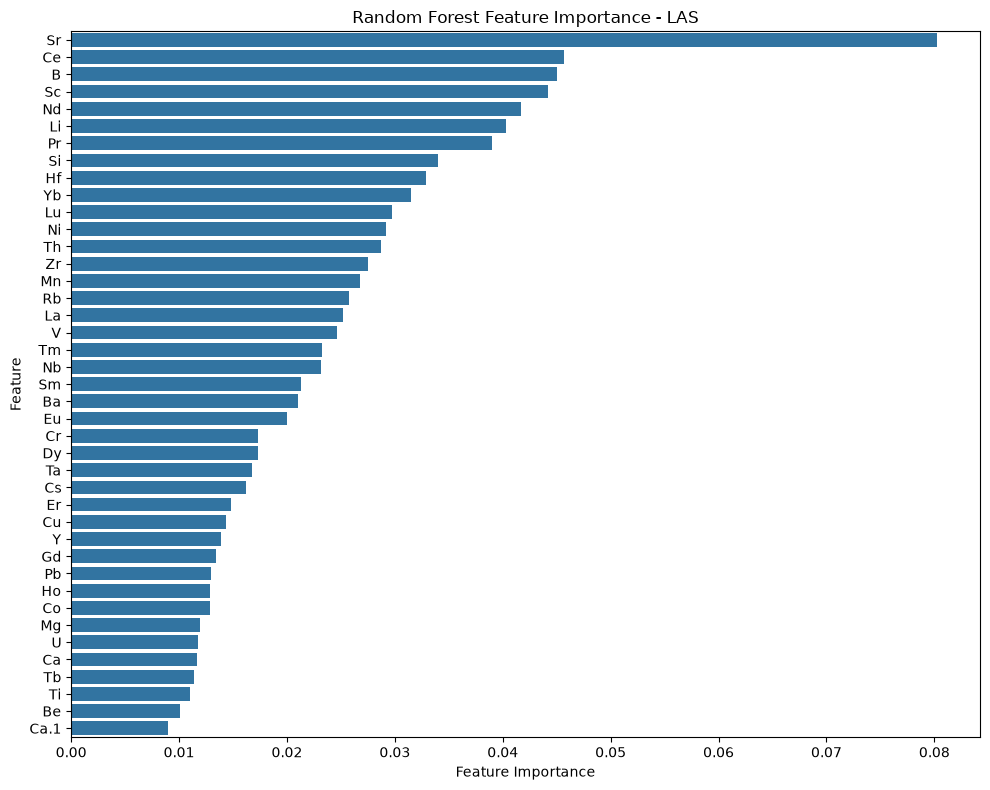

In [64]:
importance_las = pd.Series(
    rf_las.named_steps['model'].feature_importances_,
    index=X_las.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=importance_las.values, y=importance_las.index)
plt.title('Random Forest Feature Importance - LAS')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### ROC Curve: EMPA Random Forest (One-vs-Rest)
Evaluates class-wise discrimination using ROC curves and AUC. `label_binarize` converts the target labels into a binary format for one-vs-rest analysis, while `predict_proba()` provides class probability estimates. Each curve represents one class against the remaining classes. An AUC of 1.0 indicates perfect discrimination, while 0.5 indicates random-level performance.

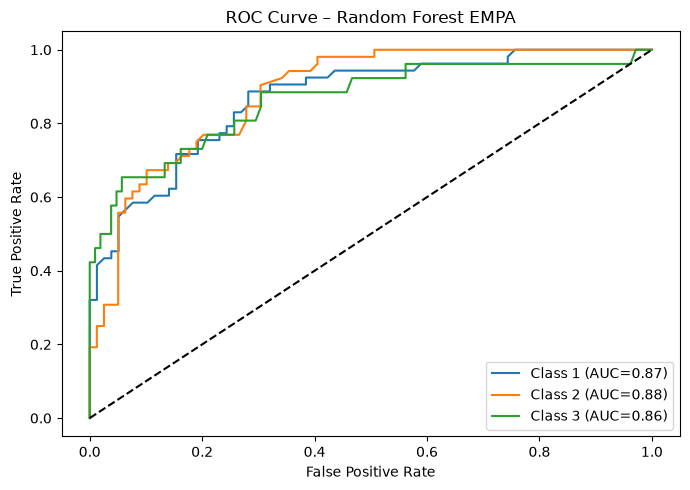

In [65]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test_empa, classes=[1,2,3])
y_score = rf_empa.predict_proba(X_test_empa)

fig, ax = plt.subplots(figsize=(7,5))
for i, cls in enumerate([1,2,3]):
    fpr, tpr, _ = roc_curve(y_test_bin[:,i], y_score[:,i])
    ax.plot(fpr, tpr, label=f'Class {cls} (AUC={auc(fpr,tpr):.2f})')
ax.plot([0,1],[0,1],'k--')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve – Random Forest EMPA'); ax.legend(); plt.tight_layout(); plt.show()

## Conclusion

This study investigated the classification of volcanic rock age groups using major-element geochemical features from EMPA and trace-element features from Laser Ablation Spectroscopy (LAS). Four classifiers were evaluated: Logistic Regression, Random Forest, XGBoost, and a multilayer perceptron (MLP).

On the held-out EMPA test set, Random Forest achieved the strongest results, with 74.0% accuracy and a macro-F1 score of 0.715. XGBoost performed similarly, achieving 73.3% accuracy and a macro-F1 score of 0.705. Logistic Regression achieved 65.6% accuracy, while the MLP achieved 71.8%. These results suggest that nonlinear models may be beneficial for the EMPA feature set, although further validation is required.

On the LAS test set, XGBoost achieved the highest performance, with 89.5% accuracy and a macro-F1 score of 0.895. Logistic Regression, Random Forest, and MLP achieved accuracies of 86.8%. However, the LAS test set contained only 38 observations, so these results should be interpreted cautiously and evaluated alongside the five-fold cross-validation results.

Class-level evaluation revealed that class 3 was particularly challenging for the EMPA models, with Random Forest and XGBoost each achieving 50% recall for this class. This highlights the importance of considering macro-averaged metrics and individual class performance rather than relying on accuracy alone.

The feature-correlation analysis also revealed relationships between geochemical variables, particularly among elements in the LAS dataset. Random Forest feature-importance analysis provides an additional means of investigating which features contribute to predictions, although impurity-based importance should not be interpreted as evidence of causation.

Five-fold stratified cross-validation provided a complementary assessment of model performance. For EMPA, the MLP achieved the highest mean macro-F1 score (0.775), followed by XGBoost (0.734), Random Forest (0.711), and Logistic Regression (0.685). For LAS, Logistic Regression achieved the highest mean macro-F1 score (0.841), followed by Random Forest (0.794), XGBoost (0.787), and MLP (0.782).

The cross-validation rankings differed from those obtained on the held-out test sets, where Random Forest performed best on EMPA and XGBoost performed best on LAS. This variation indicates that model rankings depend on the evaluation samples and that the available results do not establish a universally superior classifier. Further validation would help assess the stability and generalisability of these findings.

Overall, the experiments demonstrate the potential of geochemical features for volcanic rock age classification. Further work should examine cross-validation stability, the influence of correlated features, and the effect of repeated or duplicate measurements on evaluation. These checks will help establish whether the observed performance generalises beyond the current data split.

**Appendix**

In [66]:
# Check exact feature-vector overlap across train/test sets
empa_overlap = X_train_empa.merge(
    X_test_empa.drop_duplicates(),
    on=empa_col,
    how='inner'
)

las_overlap = X_train_las.merge(
    X_test_las.drop_duplicates(),
    on=las_col,
    how='inner'
)

print("EMPA overlapping feature vectors:", len(empa_overlap))
print("LAS overlapping feature vectors:", len(las_overlap))

EMPA overlapping feature vectors: 2
LAS overlapping feature vectors: 25


In [67]:
# drop_duplicates for EMPA — commented out per supervisor instruction.
# If re-enabled, keep='first' retains the first occurrence of each duplicate group.

#df_empa = df_empa.drop_duplicates(subset=empa_col, keep='first')

In [68]:
# drop_duplicates for LAS — commented out per supervisor instruction.
#df_las = df_las.drop_duplicates(subset=las_col, keep='first')

In [69]:
# Debug cell — checks for feature-level overlap between EMPA train/test splits.
# Commented out before submission. Confirmed no overlap in prior debugging session.
#set(map(tuple, X_train_empa.values)) & set(map(tuple, X_test_empa.values))

In [70]:
# Debug cell — same feature-level overlap check for LAS splits.
#set(map(tuple, X_train_las.values)) & set(map(tuple, X_test_las.values))

In [71]:
# Debug cell — checks whether any training indices appear in the test index.
# Returned False → no index-level leakage. Feature-level leakage is separate.
#print(X_train_las.index.isin(X_test_las.index).any())

In [72]:
# Debug cell — identifies all LAS rows with duplicate feature vectors.
# Was used to diagnose the 100% accuracy issue in XGBoost LAS model.
# Kept for audit trail but commented out for submission cleanliness.
# Are there near-duplicate geochemical measurements?
# dupes = df_las[las_col].duplicated(keep=False)
# print(f"Duplicate geochemical rows: {dupes.sum()}")
# print(df_las[dupes].sort_values(las_col[:3]))